#  Flight Delay & Cancellation Analysis
## Week 3: THE CLEANING SPRINT

### Course: 24ADI204 – Data Science and Visualization
### Project Type: Hack-A-BIT (Visual Storytelling Challenge)


Week 3: Data Cleaning & Engineering Sprint
Objective: transform the raw flight data into an analysis-ready dataset by handling missing values, fixing data types, and managing outliers using domain-specific logic.

Key Strategies Applied:
1.  **Domain-Specific Imputation:** Filling missing delay values with 0.0 (On-Time) instead of statistical mean/median.
2.  **Structural Dropping:** Removing cancelled flights that never arrived.
3.  **Feature Engineering:** Converting integer times (e.g., `1430`) to standard time objects (`14:30`).
4.  **Winsorization:** Capping extreme delay outliers at 24 hours to preserve data distribution.

**Loading Dataset**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load the raw flight delay dataset
df = pd.read_csv("../merge/flight_delay_jan_jul_oct_uncleaned.csv")

# Displaying first few rows to verify loading
df.head()



,YEAR,MONTH,DAY_OF_MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,DEST_AIRPORT_ID,...,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,832,757.0,-35.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,1450,1437.0,-13.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,850,821.0,-29.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,1917,1851.0,-26.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,2024,1,1,9E,10208,1020803,30208,AGS,"Augusta, GA",10397,...,2010,1947.0,-23.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [6]:
df.describe()
df_before = df.copy()


In [7]:
df['ARR_DELAY'].max()


np.float64(3803.0)

**Missing Value Analysis (Before Cleaning)**

The dataset was first analyzed to identify the presence and extent of missing values across all attributes.

 1. Initial Data Audit (Missing Value Analysis)
We first quantify the missingness in the dataset to decide between Imputation and Dropping.
* High Missingness (~78%): Columns like `WEATHER_DELAY` are empty for on-time flights. This is *Structural Missingness*, not data error.
* Low Missingness (~2.5%): Columns like `ARR_TIME` are empty for Cancelled/Diverted flights.

In [8]:
df.isnull().sum()
(df.isnull().sum() / len(df)) * 100


YEAR                      0.000000
MONTH                     0.000000
DAY_OF_MONTH              0.000000
OP_UNIQUE_CARRIER         0.000000
ORIGIN_AIRPORT_ID         0.000000
ORIGIN_AIRPORT_SEQ_ID     0.000000
ORIGIN_CITY_MARKET_ID     0.000000
ORIGIN                    0.000000
ORIGIN_CITY_NAME          0.000000
DEST_AIRPORT_ID           0.000000
DEST_AIRPORT_SEQ_ID       0.000000
DEST_CITY_MARKET_ID       0.000000
DEST                      0.000000
CRS_DEP_TIME              0.000000
DEP_TIME                  2.437324
DEP_DELAY                 2.443388
CRS_ARR_TIME              0.000000
ARR_TIME                  2.528679
ARR_DELAY                 2.757290
CANCELLED                 0.000000
DIVERTED                  0.000000
CARRIER_DELAY            78.378763
WEATHER_DELAY            78.378763
NAS_DELAY                78.378763
SECURITY_DELAY           78.378763
LATE_AIRCRAFT_DELAY      78.378763
dtype: float64

This analysis helped in selecting appropriate imputation strategies for different types of features.

**Identification of Numerical and Categorical Attributes**



In [9]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns


**Handling Missing Values (Imputation Strategy)**



 2. Domain-Specific Imputation Strategy
We avoid generic median/mean imputation which would introduce bias (e.g., falsifying delays for on-time flights).

Action 1 (Delay Causes): Filled `NaN` in `CARRIER_DELAY`, `WEATHER_DELAY`, etc., with 0.0.
    *  Rationale: A missing value in the BTS dataset implies the flight was "On Time" (0 minutes delay).
Action 2 (Cancelled Flights): Dropped rows with missing `ARR_TIME` or `ARR_DELAY`.
    * Rationale:These represent cancelled flights. We cannot calculate arrival delay for a flight that never landed.

In [10]:
delay_cols = ['CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 
              'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
df[delay_cols] = df[delay_cols].fillna(0)


df.dropna(subset=['ARR_DELAY', 'ARR_TIME'], inplace=True)


remaining_num_cols = df.select_dtypes(include=np.number).columns
for col in remaining_num_cols:
    if df[col].isnull().sum() > 0:
        print(f"Imputing {col} with Median...")
        df[col] = df[col].fillna(df[col].median())



**Verification of Missing Value Removal**

In [11]:
df.isnull().sum()


YEAR                     0
MONTH                    0
DAY_OF_MONTH             0
OP_UNIQUE_CARRIER        0
ORIGIN_AIRPORT_ID        0
ORIGIN_AIRPORT_SEQ_ID    0
ORIGIN_CITY_MARKET_ID    0
ORIGIN                   0
ORIGIN_CITY_NAME         0
DEST_AIRPORT_ID          0
DEST_AIRPORT_SEQ_ID      0
DEST_CITY_MARKET_ID      0
DEST                     0
CRS_DEP_TIME             0
DEP_TIME                 0
DEP_DELAY                0
CRS_ARR_TIME             0
ARR_TIME                 0
ARR_DELAY                0
CANCELLED                0
DIVERTED                 0
CARRIER_DELAY            0
WEATHER_DELAY            0
NAS_DELAY                0
SECURITY_DELAY           0
LATE_AIRCRAFT_DELAY      0
dtype: int64

Time format 
 3. Feature Engineering: Time Formatting
The Issue: The raw dataset stores time as integers (e.g., `1430` for 2:30 PM). This prevents accurate duration calculations (since $1430 - 1350 = 80$, but the real time difference is 40 minutes).

The Fix: We apply a custom transformation to convert these integers into standard `HH:MM` string format.

In [12]:

def format_time(x):
    if pd.isna(x):
        return x
    if x == 2400: return '23:59'
    s = str(int(x)).zfill(4) 
    return f"{s[:2]}:{s[2:]}" 

time_cols = ['CRS_DEP_TIME', 'CRS_ARR_TIME']
for col in time_cols:
    df[col] = df[col].apply(format_time)

print(" Time columns formatted successfully (e.g., 1430 -> 14:30)")

 Time columns formatted successfully (e.g., 1430 -> 14:30)


4. Outlier Management: Winsorization (Capping)
The Discovery: The dataset contains extreme delays up to 52 hours (3000+ mins).
The Strategy: Instead of deleting these "Storm Events" (which are critical for our analysis), we apply Capping at 24 hours (1440 minutes).

* Threshold: `1440 minutes` (24 Hours).
* Method: Any delay > 1440 is set to 1440.
* Benefit: This preserves the fact that a massive delay occurred without allowing the extreme outlier to skew our visualizations and statistical models.

In [13]:
upper_limit = 1440 # 24 Hours

outlier_cols = ['DEP_DELAY', 'ARR_DELAY', 'CARRIER_DELAY',
                'WEATHER_DELAY', 'NAS_DELAY', 'LATE_AIRCRAFT_DELAY']

for col in outlier_cols:
    # If a delay is > 1440, set it to 1440. Otherwise leave it alone.
    df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])

print(f" Outliers capped at {upper_limit} minutes. No valid flights were deleted.")
print("New Max Delay:", df['ARR_DELAY'].max()) # Should be 1440.0

 Outliers capped at 1440 minutes. No valid flights were deleted.
New Max Delay: 1440.0


**Outlier Detection Using Boxplots**



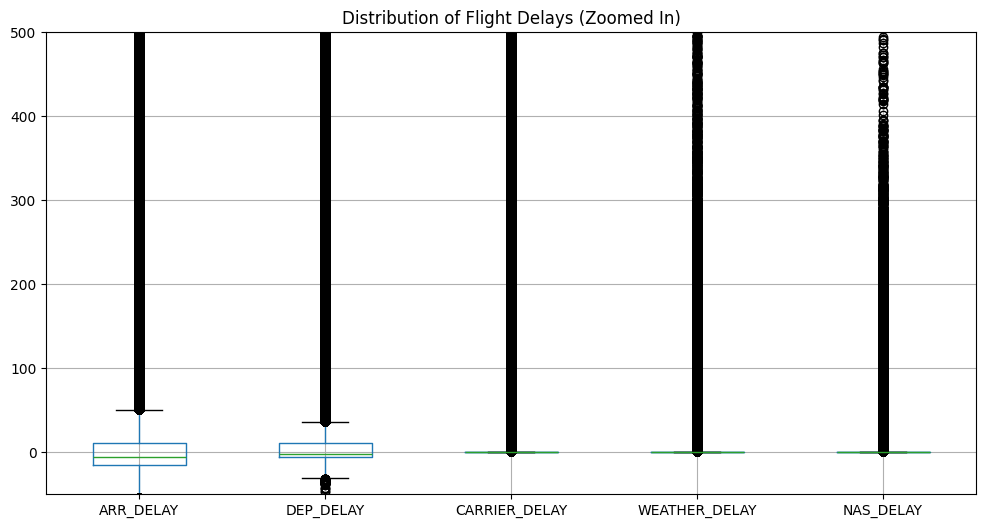

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns


delay_cols = ['ARR_DELAY', 'DEP_DELAY', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY']

existing_delays = [c for c in delay_cols if c in df.columns]

plt.figure(figsize=(12, 6))
df[existing_delays].boxplot()
plt.title("Distribution of Flight Delays (Zoomed In)")
plt.ylim(-50, 500)
plt.show()

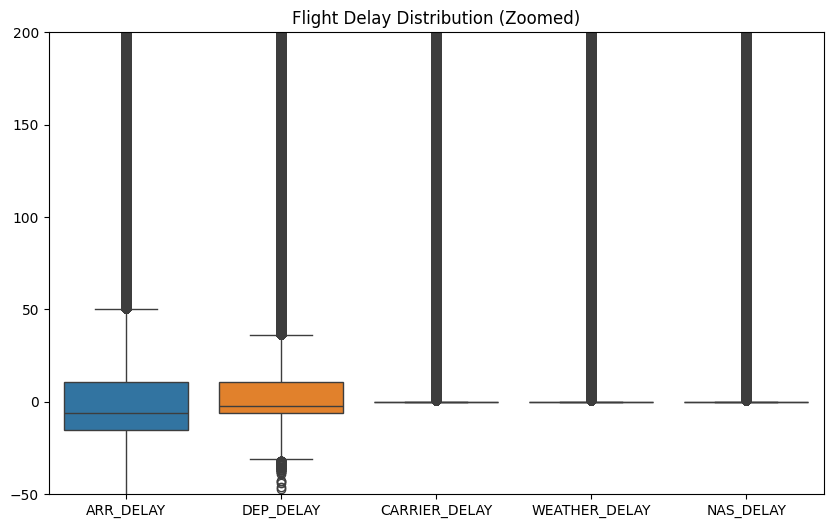

In [15]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['ARR_DELAY','DEP_DELAY','CARRIER_DELAY','WEATHER_DELAY','NAS_DELAY']])
plt.ylim(-50, 200)   # zoom into normal delays
plt.title("Flight Delay Distribution (Zoomed)")
plt.show()

Capping of overdelay flights:

**Outlier Detection – Z-Score Method**
4. Outlier Analysis and Handling Strategy
Statistical Detection We first applied Z-Score Analysis to quantify the extremity of delays. The analysis revealed Z-Scores exceeding 50.0, indicating deviations far beyond the normal distribution where a Z-Score greater than 3 is typically considered an outlier.

Cleaning Decision Simply removing rows with high Z-Scores would eliminate valid flights impacted by severe weather events. To preserve these critical data points for analysis while maintaining statistical stability, we chose Winsorization (Capping) at 1440 minutes (24 hours) instead of deletion.

In [16]:
from scipy import stats
import numpy as np

z_scores = np.abs(stats.zscore(df[['ARR_DELAY', 'DEP_DELAY']].dropna()))
max_z = z_scores.max()
print(f"Max Z-Score detected: {max_z:.2f}")

upper_limit = 1440
outlier_cols = ['DEP_DELAY', 'ARR_DELAY', 'CARRIER_DELAY', 
                'WEATHER_DELAY', 'NAS_DELAY', 'LATE_AIRCRAFT_DELAY']

for col in outlier_cols:
    df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])

print(f"Outliers capped at {upper_limit} minutes.")
print(f"New Max Arrival Delay: {df['ARR_DELAY'].max()}")
print(f"Data Shape: {df.shape}")

Max Z-Score detected: 24.28
Outliers capped at 1440 minutes.
New Max Arrival Delay: 1440.0
Data Shape: (1747822, 26)


In [ ]:
print("Before cleaning:", df_before.shape)
print("After cleaning:", df.shape)


Before cleaning: (1747822, 26)
After cleaning: (1797381, 26)


**Final Cleaned Dataset Summary**

 5. Final Data Verification
We verify the cleaning process by checking the descriptive statistics.
Max Delay: Should be capped at 1440.0.
* Missing Values: Should be 0.
* Time Columns: Should look like valid time strings.

The dataset is now clean and ready for Week 4: Exploratory Data Analysis (EDA).

In [22]:
def delay_category(x):
    if x <= 0:
        return "On-Time/Early"
    elif x <= 30:
        return "Slight Delay"
    elif x <= 120:
        return "Moderate Delay"
    else:
        return "Severe Delay"

df['DelayCategory'] = df['ARR_DELAY'].apply(delay_category)
df['DelayCategory'].value_counts()


DelayCategory
On-Time/Early     1092530
Slight Delay       401911
Moderate Delay     193229
Severe Delay        60152
Name: count, dtype: int64

In [19]:
df.describe()


,YEAR,MONTH,DAY_OF_MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_TIME,DEP_DELAY,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
count,1747822.0,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1747822.0,1747822.0,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06
mean,2024.0,6.240954e+00,1.598958e+01,1.264525e+04,1.264529e+06,3.173505e+04,1.264578e+04,1.264582e+06,3.173557e+04,1.330450e+03,1.433428e+01,1.459890e+03,8.991615e+00,0.0,0.0,6.024398e+00,1.037484e+00,2.779290e+00,2.994527e-02,6.747651e+00
std,0.0,3.657641e+00,8.949267e+00,1.532606e+03,1.532604e+05,1.323885e+03,1.532763e+03,1.532761e+05,1.324141e+03,5.095775e+02,5.872193e+01,5.463739e+02,6.098878e+01,0.0,0.0,3.840437e+01,1.714598e+01,1.475774e+01,1.654477e+00,3.292781e+01
min,2024.0,1.000000e+00,1.000000e+00,1.013500e+04,1.013506e+06,3.007000e+04,1.013500e+04,1.013506e+06,3.007000e+04,1.000000e+00,-6.600000e+01,1.000000e+00,-9.100000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,1.000000e+00,8.000000e+00,1.129200e+04,1.129202e+06,3.061500e+04,1.129200e+04,1.129202e+06,3.061500e+04,9.080000e+02,-6.000000e+00,1.044000e+03,-1.500000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,7.000000e+00,1.600000e+01,1.288900e+04,1.288904e+06,3.145300e+04,1.288900e+04,1.288904e+06,3.145300e+04,1.324000e+03,-2.000000e+00,1.502000e+03,-6.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,1.000000e+01,2.400000e+01,1.402700e+04,1.402702e+06,3.246700e+04,1.405700e+04,1.405702e+06,3.246700e+04,1.745000e+03,1.100000e+01,1.918000e+03,1.100000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2024.0,1.000000e+01,3.100000e+01,1.686900e+04,1.686902e+06,3.599100e+04,1.686900e+04,1.686902e+06,3.599100e+04,2.400000e+03,1.440000e+03,2.400000e+03,1.440000e+03,0.0,0.0,1.440000e+03,1.440000e+03,1.431000e+03,1.005000e+03,1.440000e+03


**Saved Cleaned Dataset**

In [20]:
df.to_csv("flight_delay_cleaned.csv", index=False)

In [ ]:
import os
os.listdir()


['04_eda_analysis.ipynb', 'DSV_team2_Week_3.ipynb', 'flight_delay_cleaned.csv']

**Week 3 Observations & Conclusion**

Missing values in delay-related columns were identified and handled using appropriate imputation strategies.


Outlier detection was performed on delay-related features using Z-score and visualized through boxplots.

Extreme delay records were capped while retaining the majority of valid data.

**Next Phase:**
Week 4 will focus on Exploratory Data Analysis (EDA), including univariate and bivariate analysis and visualization of data distributions.